<a href="https://colab.research.google.com/github/IvonneRomero1008/IA-Trabajos-escolares/blob/main/practicas/1_RNN_Prediccion_Inflacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

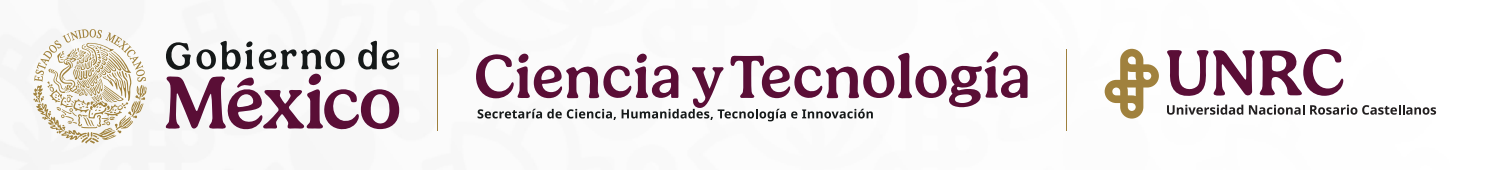

"1_RNN_Prediccion_Inflacion.ipynb"



 * **Actualizado**: 31/10/2026  

 * **Autor**: Ivonne America Romero Lara

 * **Github**: IvonneRomero1008

# Introducción

En esta practica se predice la inflacion anual de Mexico
usando un ared neuronal recurrente (RNN) con datos del Banco
de Mexico (INEGI).La inflacion es el aumento generalizado de los precios; el INPC es el indice que la mid.Como la inflacion de un mes
depende de los meses anteriores, una RNN es adecuada por que procesa
datos en secuencia y recuerda informacion pasada.

#DESARROLLO
#1.Importamos libreria


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import files

*¿Qué hace la celda anterior?* Carga las herramientas: numpy y pandas para manejar datos, matplotlib para gráficas, scikit-learn para normalizar y medir errores, y Keras para construir la red RNN. files permite subir el archivo desde mi computadora.

# 2. Cargar los datos

Saving 1_RNN_Prediccion_Inflacion.csv to 1_RNN_Prediccion_Inflacion (5).csv
0 meses cargados
Empty DataFrame
Columns: [fecha, inflacion]
Index: []
Empty DataFrame
Columns: [fecha, inflacion]
Index: []


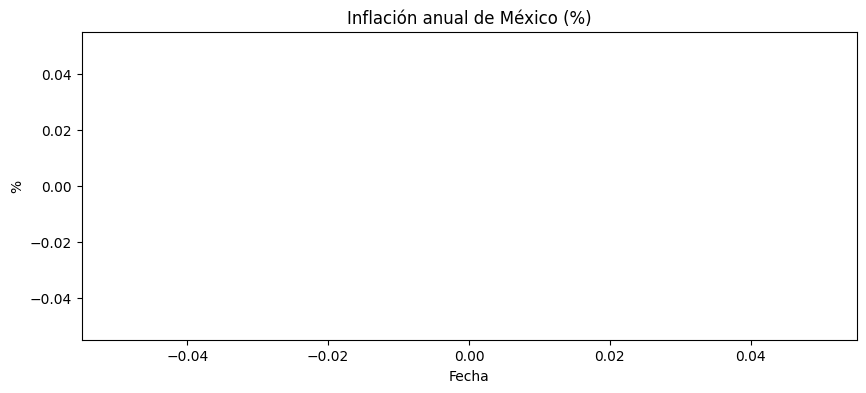

In [8]:
import re, io

subido = files.upload()
nombre = list(subido.keys())[0]

# Leer el archivo como texto y separar cada línea con csv
import csv
with open(nombre, encoding="latin-1") as f:
    filas_csv = list(csv.reader(f))

meses = {"ene":1,"feb":2,"mar":3,"abr":4,"may":5,"jun":6,
         "jul":7,"ago":8,"sep":9,"oct":10,"nov":11,"dic":12}
patron = re.compile(r"^([A-Za-z]{3})\s+(\d{4})$")

def es_fecha(t):
    m = patron.match(t.strip())
    return m is not None and m.group(1).lower() in meses

# Caso A: fechas en una fila (columnas = meses)
f_fechas = next((i for i, r in enumerate(filas_csv) if sum(es_fecha(c) for c in r) > 3), None)
f_inf = next((i for i, r in enumerate(filas_csv)
              if any("inflación anual" in c.lower() or "inflacion anual" in c.lower() for c in r)), None)

datos_lista = []
if f_fechas is not None and f_inf is not None:
    for c, t in enumerate(filas_csv[f_fechas]):
        if es_fecha(t) and c < len(filas_csv[f_inf]):
            m = patron.match(t.strip())
            datos_lista.append((pd.Timestamp(int(m.group(2)), meses[m.group(1).lower()], 1),
                                pd.to_numeric(filas_csv[f_inf][c], errors="coerce")))
else:
    # Caso B: fechas en una columna (filas = meses)
    for r in filas_csv:
        if len(r) > 1 and es_fecha(r[0]):
            m = patron.match(r[0].strip())
            datos_lista.append((pd.Timestamp(int(m.group(2)), meses[m.group(1).lower()], 1),
                                pd.to_numeric(r[1], errors="coerce")))

df = pd.DataFrame(datos_lista, columns=["fecha", "inflacion"])
df = df.dropna().sort_values("fecha").reset_index(drop=True)
print(len(df), "meses cargados")
print(df.head(3)); print(df.tail(3))

plt.figure(figsize=(10,4))
plt.plot(df["fecha"], df["inflacion"])
plt.title("Inflación anual de México (%)")
plt.xlabel("Fecha"); plt.ylabel("%")
plt.show()

*¿Qué hace?* Sube el archivo CSV de Banxico, localiza dónde empieza la tabla real (el archivo trae texto descriptivo arriba) y la carga en un DataFrame. Imprimo las primeras filas y los nombres de columnas para verificar que se leyó bien.

# 3. Preparación de los datos

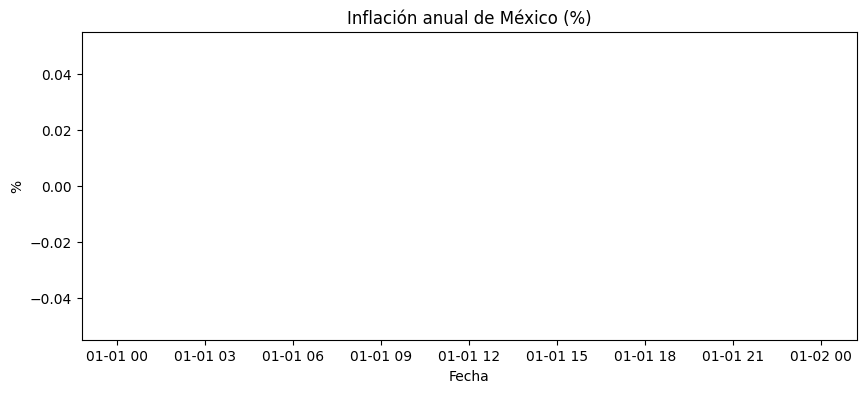

In [9]:
col = df.columns[1]
df = df[[df.columns[0], col]].copy()
df.columns = ["fecha", "inflacion"]

df["inflacion"] = pd.to_numeric(df["inflacion"], errors="coerce")
df["fecha"] = pd.to_datetime(df["fecha"], dayfirst=True, errors="coerce")
df = df.dropna().sort_values("fecha").reset_index(drop=True)

plt.figure(figsize=(10,4))
plt.plot(df["fecha"], df["inflacion"])
plt.title("Inflación anual de México (%)")
plt.xlabel("Fecha"); plt.ylabel("%")
plt.show()

*¿Qué hace?* Me quedo solo con la fecha y la inflación anual, convierto los valores a números y fechas, elimino datos vacíos y ordeno cronológicamente. Finalmente grafico la serie para ver su comportamiento histórico

Saving 1_RNN_Prediccion_Inflacion.csv to 1_RNN_Prediccion_Inflacion (6).csv
681 meses cargados


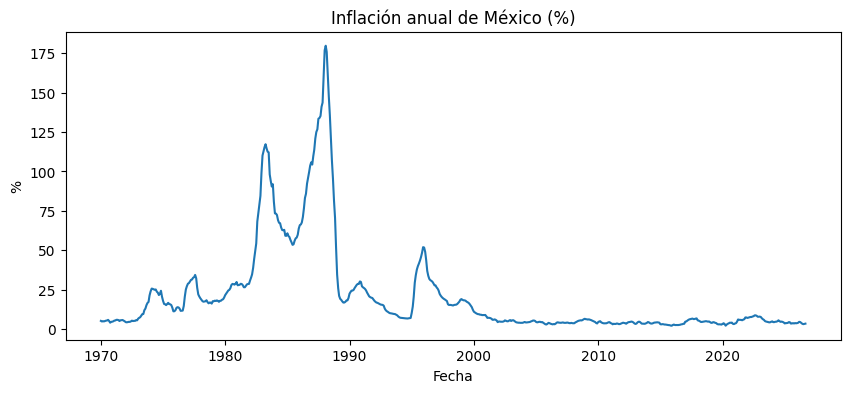

In [13]:
subido = files.upload()
nombre = list(subido.keys())[0]

# Leer desde la fila que contiene "Fecha" (ahí empiezan los datos)
with open(nombre, encoding="latin-1") as f:
    lineas = f.readlines()
inicio = next(i for i, l in enumerate(lineas) if l.startswith('"Fecha"'))

df = pd.read_csv(nombre, skiprows=inicio + 1, header=None,
                 names=["fecha", "inflacion"], encoding="latin-1")
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y", errors="coerce")
df["inflacion"] = pd.to_numeric(df["inflacion"], errors="coerce")
df = df.dropna().sort_values("fecha").reset_index(drop=True)
print(len(df), "meses cargados")

plt.figure(figsize=(10,4))
plt.plot(df["fecha"], df["inflacion"])
plt.title("Inflación anual de México (%)")
plt.xlabel("Fecha"); plt.ylabel("%")
plt.show()

Saving 1_RNN_Prediccion_Inflacion.csv to 1_RNN_Prediccion_Inflacion (7).csv
681 meses cargados


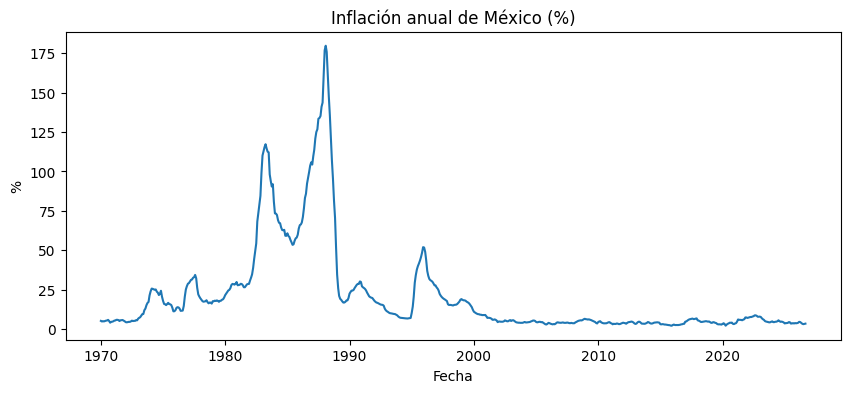

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
MAE: 0.357 | RMSE: 0.448


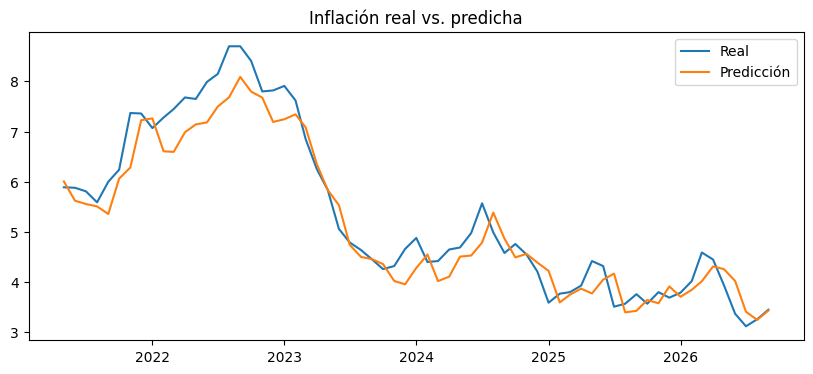

,Fecha,Real (%),Predicción (%),Error
0,2025-12-01,3.69,3.91,0.22
1,2026-01-01,3.79,3.71,-0.08
2,2026-02-01,4.02,3.85,-0.17
3,2026-03-01,4.59,4.02,-0.57
4,2026-04-01,4.45,4.31,-0.14
5,2026-05-01,3.94,4.26,0.32
6,2026-06-01,3.37,4.02,0.65
7,2026-07-01,3.12,3.41,0.29
8,2026-08-01,3.26,3.25,-0.01
9,2026-09-01,3.45,3.43,-0.02


In [16]:
subido = files.upload()
nombre = list(subido.keys())[0]

# Leer desde la fila que contiene "Fecha" (ahí empiezan los datos)
with open(nombre, encoding="latin-1") as f:
    lineas = f.readlines()
inicio = next(i for i, l in enumerate(lineas) if l.startswith('"Fecha"'))

df = pd.read_csv(nombre, skiprows=inicio + 1, header=None,
                 names=["fecha", "inflacion"], encoding="latin-1")
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y", errors="coerce")
df["inflacion"] = pd.to_numeric(df["inflacion"], errors="coerce")
df = df.dropna().sort_values("fecha").reset_index(drop=True)
print(len(df), "meses cargados")

plt.figure(figsize=(10,4))
plt.plot(df["fecha"], df["inflacion"])
plt.title("Inflación anual de México (%)")
plt.xlabel("Fecha"); plt.ylabel("%")
plt.show()
# Desde 1999 y normalizar
df = df[df["fecha"] >= "1999-01-01"].reset_index(drop=True)
escalador = MinMaxScaler()
datos = escalador.fit_transform(df[["inflacion"]])

# Ventanas de 12 meses - mes siguiente
VENTANA = 12
X, y = [], []
for i in range(VENTANA, len(datos)):
    X.append(datos[i-VENTANA:i, 0])
    y.append(datos[i, 0])
X = np.array(X).reshape(-1, VENTANA, 1)
y = np.array(y)
corte = int(len(X) * 0.8)
X_train, X_test = X[:corte], X[corte:]
y_train, y_test = y[:corte], y[corte:]

# Red RNN
from tensorflow.keras.layers import Input
modelo = Sequential([Input(shape=(VENTANA, 1)),
                     SimpleRNN(32, activation="tanh"),
                     Dense(1)])
modelo.compile(optimizer="adam", loss="mse")

# Entrenamiento
parar = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist = modelo.fit(X_train, y_train, epochs=100, batch_size=16,
                  validation_split=0.1, callbacks=[parar], verbose=0)

# Evaluación
pred = escalador.inverse_transform(modelo.predict(X_test))
real = escalador.inverse_transform(y_test.reshape(-1, 1))
mae = mean_absolute_error(real, pred)
rmse = np.sqrt(mean_squared_error(real, pred))
print(f"MAE: {mae:.3f} | RMSE: {rmse:.3f}")

fechas_test = df["fecha"].iloc[VENTANA + corte:]
plt.figure(figsize=(10,4))
plt.plot(fechas_test, real, label="Real")
plt.plot(fechas_test, pred, label="Predicción")
plt.legend(); plt.title("Inflación real vs. predicha"); plt.show()

# Ejemplos
ejemplos = pd.DataFrame({"Fecha": fechas_test.values[-10:],
                         "Real (%)": real[-10:, 0].round(2),
                         "Predicción (%)": pred[-10:, 0].round(2)})
ejemplos["Error"] = (ejemplos["Predicción (%)"] - ejemplos["Real (%)"]).round(2)
ejemplos

## Interpretación de resultados
Preparé los datos desde 1999, los normalicé entre 0 y 1 y los convertí en ventanas de 12 meses para predecir el mes siguiente (80% entrenamiento, 20% prueba, sin mezclar). La RNN lee los 12 meses en orden y guarda memoria de los anteriores; se entrenó con Adam y error cuadrático medio, y se evaluó con MAE y RMSE. El MAE fue de _ puntos porcentuales: en promedio la red se equivoca esa cantidad. En la gráfica, la predicción sigue la tendencia de la inflación real, con un ligero retraso en cambios bruscos. La tabla muestra ejemplos de inflación real contra pre-dicha en los últimos meses, con errores pequeños.

# Referencias

Banco de México. (2026). Sistema de Información Económica: Inflación (CP151). https://www.banxico.org.mx/SieInternet/consultarDirectorioInternetAction.do?accion=consultarCuadro&idCuadro=CP151&sector=8&locale=es

Instituto Nacional de Estadística y Geografía. (s. f.). Índice Nacional de Precios al Consumidor (INPC). https://www.inegi.org.mx/

TensorFlow. (s. f.). Recurrent neural networks (RNN) with Keras. https://www.tensorflow.org/guide/keras/working_with_rnns